# 09 · Step 9: Measurement playbook (gate K8)
**The question:** once a company runs Nudge every month, how does it keep **proving** the profit is real, and know when the model has gone **stale**?

Steps 1-8 rested on one clean random test. Once you start targeting, that clean test disappears unless you protect it on purpose.

| Part | Question |
|---|---|
| A | Why must a control group exist? (naive vs fair report, a decision that flips) |
| B | How big should the permanent control group be, and what does it cost? |
| C | How do we keep learning? (exploration, recorded chances, cost of a stale model) |
| D | When is the model stale? (real month-by-month drift, lift-ladder alarm) |
| E | What is the best time to send? (test design) |
| F | The one-page playbook |

## Cell 0 · Setup

In [12]:
import pandas as pd, numpy as np, duckdb, time, warnings
warnings.filterwarnings('ignore')
import matplotlib.pyplot as plt, lightgbm as lgb
from pathlib import Path
from sklift.metrics import qini_auc_score, uplift_at_k
from nudge_engine import sample_size_per_group, min_detectable_lift, psi, drift_report
pd.set_option('display.width', 200); pd.set_option('display.max_columns', 20); pd.set_option('display.max_colwidth', 90)
X5 = Path('..') / 'data_x5' / 'features'
MARGIN, SMS = 150, 0.10          # ₹ profit per extra purchase and ₹ per SMS, as in Step 8
CHECKS = {}
t0 = time.time()
P = duckdb.sql(f"SELECT * FROM '{(X5 / 'customer_profiles.parquet').as_posix()}'").df()
P = pd.concat([P, pd.get_dummies(P.gender, prefix='gender').astype(int)], axis=1)
XC = [c for c in P.columns if c not in {'client_id', 'gender', 'treatment_flg', 'target', 'in_experiment'}]
P[XC] = P[XC].astype('float32')
hs = duckdb.sql(f"SELECT client_id, champion FROM '{(X5 / 'holdout_scores.parquet').as_posix()}'").df()
ur = duckdb.sql(f"SELECT client_id, uplift_rank FROM '{(X5 / 'uplift_scores_champion.parquet').as_posix()}'").df()
ex = P[P.in_experiment == 1].merge(ur, on='client_id')
hold = ex.merge(hs, on='client_id'); dev = ex[~ex.client_id.isin(hs.client_id)].reset_index(drop=True)
new = P[P.in_experiment == 0]                     # customers outside the test = 'next month's customers'
BASE = ex[ex.treatment_flg == 0].target.mean(); LIFT = ex[ex.treatment_flg == 1].target.mean() - BASE
print(f'experiment {len(ex):,} (build {len(dev):,} | locked exam {len(hold):,}) | other customers {len(new):,} | loaded in {time.time() - t0:.0f}s')
print(f'buy rate without message {BASE:.1%} | average lift from message {100 * LIFT:.1f} pts')

experiment 200,039 (build 160,031 | locked exam 40,008) | other customers 200,123 | loaded in 1s
buy rate without message 60.3% | average lift from message 3.3 pts


## Part A · Why a control group is non-negotiable
A company messages its top 30% (by uplift). The usual campaign report counts **every buyer who got the message** as a win. The fair report compares them with look-alike customers who were held back.

,claimed buyers from campaign,claimed profit ₹
Naive report (all buyers who got the message),15650.0,2344530.0
Fair report (vs held-back look-alikes),1820.0,269670.0


buy rate messaged 52.2% vs held back 46.1%: the message caused 6.1 pts
The naive report overstates the effect 8.6x: only 12% of these buyers were caused by the message.


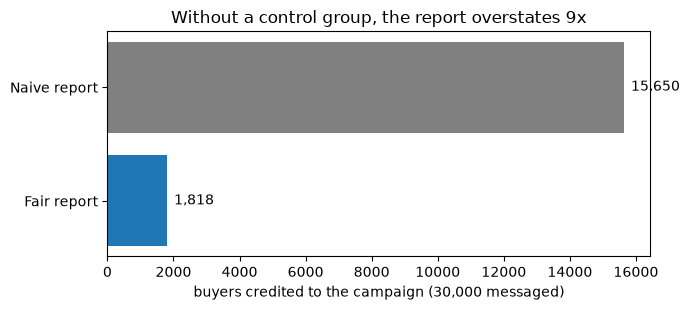

In [13]:
top = hold.champion >= hold.champion.quantile(0.7); g = hold[top]
msg_rate = g[g.treatment_flg == 1].target.mean(); ctl_rate = g[g.treatment_flg == 0].target.mean()
N = 30_000                                        # top 30% of 1 lakh customers, all messaged
naive_buyers, fair_buyers = msg_rate * N, (msg_rate - ctl_rate) * N
A = pd.DataFrame({'claimed buyers from campaign': [naive_buyers, fair_buyers],
                  'claimed profit ₹': [naive_buyers * MARGIN - N * SMS, fair_buyers * MARGIN - N * SMS]},
                 index=['Naive report (all buyers who got the message)', 'Fair report (vs held-back look-alikes)']).round(-1)
display(A)
ratio = naive_buyers / fair_buyers
print(f'buy rate messaged {msg_rate:.1%} vs held back {ctl_rate:.1%}: the message caused {100 * (msg_rate - ctl_rate):.1f} pts')
print(f'The naive report overstates the effect {ratio:.1f}x: only {fair_buyers / naive_buyers:.0%} of these buyers were caused by the message.')
CHECKS['Naive report overstates the true effect (at least 3x)'] = ratio >= 3
fig, ax = plt.subplots(figsize=(7, 3.2))
ax.barh(['Fair report', 'Naive report'], [fair_buyers, naive_buyers], color=['tab:blue', 'grey'])
for i, v in enumerate([fair_buyers, naive_buyers]): ax.text(v + 200, i, f'{v:,.0f}', va='center')
ax.set_xlabel('buyers credited to the campaign (30,000 messaged)'); ax.set_title(f'Without a control group, the report overstates {ratio:.0f}x')
plt.tight_layout(); plt.show()

**A2. The decision flip: a campaign that only looks profitable.** Suppose the company calls the **bottom half** of customers with AI voice calls (₹3.33 each). What does each report say a call earns?

In [14]:
CALL = 3.33
rows = []
for name, sel in [('Top half (high uplift)', hold.champion.rank(pct=True) > 0.5), ('Bottom half (low uplift)', hold.champion.rank(pct=True) <= 0.5)]:
    g = hold[sel]; t, c = g[g.treatment_flg == 1].target, g[g.treatment_flg == 0].target
    lift = t.mean() - c.mean(); se = np.sqrt(t.var() / len(t) + c.var() / len(c))
    rows.append({'group': name, 'naive ₹ per call': t.mean() * MARGIN - CALL, 'fair ₹ per call': lift * MARGIN - CALL,
                 'fair low95': (lift - 1.96 * se) * MARGIN - CALL, 'fair high95': (lift + 1.96 * se) * MARGIN - CALL})
A2 = pd.DataFrame(rows).set_index('group').round(2); display(A2)
b = A2.loc['Bottom half (low uplift)']
print(f"Bottom half: the naive report says ₹{b['naive ₹ per call']:.0f} profit per call; the fair report says ₹{b['fair ₹ per call']:.2f} "
      f"(range ₹{b['fair low95']:.2f} to ₹{b['fair high95']:.2f}): at best break-even. Trusting the naive report, the company would scale up a campaign that does not pay.")
CHECKS['Decision flip: naive shows big profit, fair shows break-even or loss (bottom half, AI calls)'] = (b['naive ₹ per call'] > 10) and (b['fair ₹ per call'] < 1)

,naive ₹ per call,fair ₹ per call,fair low95,fair high95
group,,,,
Top half (high uplift),78.96,3.21,1.13,5.28
Bottom half (low uplift),105.06,-0.47,-2.36,1.41


Bottom half: the naive report says ₹105 profit per call; the fair report says ₹-0.47 (range ₹-2.36 to ₹1.41): at best break-even. Trusting the naive report, the company would scale up a campaign that does not pay.


## Part B · How big should the permanent control group be?
**The trade-off:** a bigger control group measures more precisely, but every held-back customer is a lost sale.
- **Sample size per group** = customers needed in each group to detect a lift (95% confidence, 80% power).
- **Minimum detectable lift (MDE)** = the smallest lift a given split can reliably see. We want it at or below **half the expected lift** (about 1.7 pts), so a real drop in performance is caught.

**B1. Customers needed per group, for each lift we want to detect** (base buy rate as in X5):

In [15]:
B1 = pd.DataFrame([{'lift to detect (pts)': d * 100, 'customers per group': sample_size_per_group(BASE, d)} for d in [0.01, 0.015, 0.02, round(LIFT, 4), 0.05]]).set_index('lift to detect (pts)')
display(B1)
# check the formula by simulation on real X5 customers
n = sample_size_per_group(BASE, LIFT); rng = np.random.default_rng(0)
Tb, Cb = ex[ex.treatment_flg == 1].target.values, ex[ex.treatment_flg == 0].target.values; hits = 0; R = 2000
for _ in range(R):
    a, b = rng.choice(Tb, n), rng.choice(Cb, n); hits += (a.mean() - b.mean()) / np.sqrt(a.var() / n + b.var() / n) > 1.96
print(f'Formula: {n:,} per group detects the real {100 * LIFT:.2f}-pt lift 80% of the time. Simulation on real customers: {hits / R:.1%} of {R:,} repeats detected it.')
CHECKS['Sample-size formula matches simulation (power 77-83%)'] = 0.77 <= hits / R <= 0.83

,customers per group
lift to detect (pts),
1.00,37400
1.50,16582
2.00,9304
3.32,3352
5.00,1463


Formula: 3,346 per group detects the real 3.32-pt lift 80% of the time. Simulation on real customers: 79.0% of 2,000 repeats detected it.


**B2. Control share vs precision vs cost.** Cost = sales forgone by not messaging the control group = control size × lift × ₹150 − SMS saved.

control customers  MDE (pts) catches a halving of lift?  cost per campaign ₹
customers per campaign control share                                                                              
100000                 1%                          1000       4.36                         no               4900.0
                       2%                          2000       3.10                         no               9800.0
                       5%                          5000       1.99                         no              24400.0
                       10%                        10000       1.44                        yes              48800.0
                       20%                        20000       1.08                        yes              97700.0
1000000                1%                         10000       1.38                        yes              48800.0
                       2%                         20000       0.98                        yes              97700.0
                       5%                         50000       0.63                        yes             244200.0
                       10%                       100000       0.46                        yes             488500.0
                       20%                       200000       0.34                        yes             976900.0

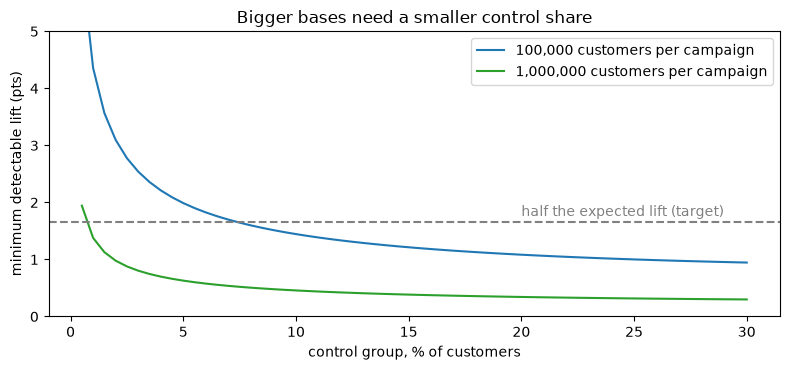

In [16]:
rows = []
for base_n in [100_000, 1_000_000]:
    for s in [0.01, 0.02, 0.05, 0.10, 0.20]:
        nc = base_n * s; mde = min_detectable_lift(base_n - nc, nc, BASE)
        rows.append({'customers per campaign': base_n, 'control share': f'{s:.0%}', 'control customers': int(nc), 'MDE (pts)': round(100 * mde, 2),
                     'catches a halving of lift?': 'yes' if mde <= LIFT / 2 else 'no', 'cost per campaign ₹': round(nc * (LIFT * MARGIN - SMS), -2)})
B2 = pd.DataFrame(rows); display(B2.set_index(['customers per campaign', 'control share']))
fig, ax = plt.subplots(figsize=(8, 3.8)); shares = np.linspace(0.005, 0.3, 60)
for base_n, col in [(100_000, 'tab:blue'), (1_000_000, 'tab:green')]:
    ax.plot(shares * 100, [100 * min_detectable_lift(base_n * (1 - s), base_n * s, BASE) for s in shares], color=col, label=f'{base_n:,} customers per campaign')
ax.axhline(100 * LIFT / 2, color='grey', ls='--'); ax.text(20, 100 * LIFT / 2 + 0.1, 'half the expected lift (target)', color='grey')
ax.set_xlabel('control group, % of customers'); ax.set_ylabel('minimum detectable lift (pts)'); ax.set_ylim(0, 5)
ax.set_title('Bigger bases need a smaller control share'); ax.legend(); plt.tight_layout(); plt.show()

**B3. Test length.** If a company can contact only so many customers a week, how many weeks until a test can read a 2-pt lift?

In [17]:
need = 2 * sample_size_per_group(BASE, 0.02)
display(pd.DataFrame([{'customers contacted per week': w, 'weeks for a 2-pt test (both groups)': int(np.ceil(need / w))} for w in [2_000, 5_000, 10_000, 50_000]]).set_index('customers contacted per week'))
print(f'A 2-pt test needs {need:,} customers in total (half contacted, half held back).')

,weeks for a 2-pt test (both groups)
customers contacted per week,
2000,10
5000,4
10000,2
50000,1


A 2-pt test needs 18,608 customers in total (half contacted, half held back).


## Part C · How do we keep learning? (random exploration)
Once a company messages **only** its top 30%, the next campaign's data has no messaged low-score customers and no held-back high-score customers. A model retrained on that data cannot tell what the message *causes*.

**The fix:** every campaign, give a small random slice of customers a random assignment (message or not), exactly like the original test, and retrain on that slice.

**The test:** retrain the same simple uplift model (T-learner) on different kinds of data, and score each on the locked exam (Qini: higher is better).

,customers,Qini,top-30% lift (pts),% of clean-test quality
training data,,,,
"Clean random test, all build customers",160031,0.0145,5.5079,100.0
"Targeted only: top 30% messaged, rest not",79872,-0.0102,1.5552,-71.0
Random exploration slice only (5%),8001,0.0080,5.1706,55.0
Random exploration slice only (10%),16003,0.0068,5.0141,47.0
Random exploration slice only (20%),32006,0.0091,5.4629,63.0
Random exploration slice only (30%),48009,0.0108,5.4404,75.0
Random exploration slice only (50%),80015,0.0111,5.5468,76.0


(average lift across everyone is 3.3 pts; a useful model puts more than that in its top 30%) | 37s


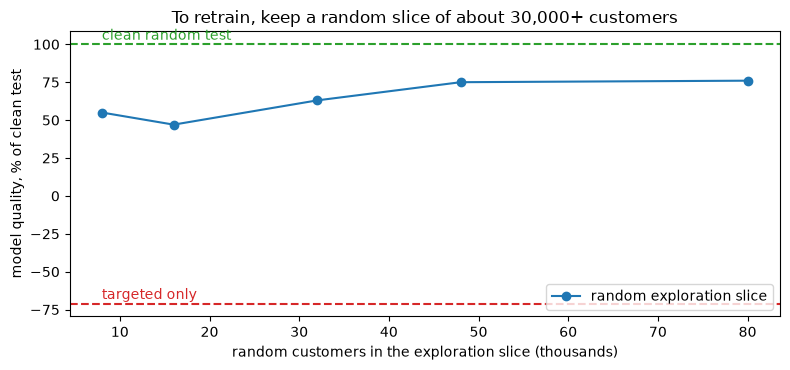

In [18]:
t0 = time.time()
def clf(): return lgb.LGBMClassifier(n_estimators=300, learning_rate=0.03, num_leaves=15, min_child_samples=300, subsample=0.8, subsample_freq=1,
                                     colsample_bytree=0.7, reg_lambda=5.0, verbose=-1, random_state=42)
def retrain_and_score(d):
    m1 = clf().fit(d.loc[d.treatment_flg == 1, XC], d.loc[d.treatment_flg == 1, 'target'])
    m0 = clf().fit(d.loc[d.treatment_flg == 0, XC], d.loc[d.treatment_flg == 0, 'target'])
    s = m1.predict_proba(hold[XC])[:, 1] - m0.predict_proba(hold[XC])[:, 1]
    return qini_auc_score(hold.target, s, hold.treatment_flg), 100 * uplift_at_k(hold.target, s, hold.treatment_flg, strategy='overall', k=0.3)
target30 = dev.uplift_rank >= dev.uplift_rank.quantile(0.7)
targeted_only = dev[(target30 & (dev.treatment_flg == 1)) | (~target30 & (dev.treatment_flg == 0))]
rows = [('Clean random test, all build customers', len(dev), *retrain_and_score(dev)),
        ('Targeted only: top 30% messaged, rest not', len(targeted_only), *retrain_and_score(targeted_only))]
for frac in [0.05, 0.10, 0.20, 0.30, 0.50]:
    q = [retrain_and_score(dev.sample(frac=frac, random_state=s)) for s in [1, 2, 3, 4]]
    rows.append((f'Random exploration slice only ({frac:.0%})', int(frac * len(dev)), np.mean([v[0] for v in q]), np.mean([v[1] for v in q])))
C = pd.DataFrame(rows, columns=['training data', 'customers', 'Qini', 'top-30% lift (pts)']).set_index('training data')
C['% of clean-test quality'] = (100 * C.Qini / C.Qini.iloc[0]).round(0); display(C.round(4))
print(f'(average lift across everyone is {100 * LIFT:.1f} pts; a useful model puts more than that in its top 30%) | {time.time() - t0:.0f}s')
expl = C[C.index.str.startswith('Random')]
CHECKS['Targeted-only retraining fails (under half the clean Qini)'] = C.Qini.iloc[1] < 0.5 * C.Qini.iloc[0]
CHECKS['Enough random exploration recovers most quality (60%+ of clean Qini)'] = (expl.Qini >= 0.6 * C.Qini.iloc[0]).any()
fig, ax = plt.subplots(figsize=(8, 3.8))
ax.plot(expl.customers / 1000, expl['% of clean-test quality'], marker='o', label='random exploration slice')
ax.axhline(100, color='tab:green', ls='--'); ax.text(expl.customers.min() / 1000, 103, 'clean random test', color='tab:green')
ax.axhline(C['% of clean-test quality'].iloc[1], color='tab:red', ls='--'); ax.text(expl.customers.min() / 1000, C['% of clean-test quality'].iloc[1] + 3, 'targeted only', color='tab:red')
ax.set_xlabel('random customers in the exploration slice (thousands)'); ax.set_ylabel('model quality, % of clean test')
ax.set_title('To retrain, keep a random slice of about 30,000+ customers'); ax.legend(loc='lower right'); plt.tight_layout(); plt.show()

**C2. What a wrongly retrained model costs, in rupees.** A model's top 30% is where the money is made (Step 8). Lost lift in that group = lost buyers.

In [19]:
good, bad = C['top-30% lift (pts)'].iloc[0], C['top-30% lift (pts)'].iloc[1]
lost = (good - bad) / 100 * 30_000 * MARGIN
print(f'Top-30% lift: clean model {good:.1f} pts vs targeted-only model {bad:.1f} pts -> about ₹{lost:,.0f} of profit lost per campaign of 1 lakh customers.')

Top-30% lift: clean model 5.5 pts vs targeted-only model 1.6 pts -> about ₹177,870 of profit lost per campaign of 1 lakh customers.


**C3. The industry fix: explore inside every decision, and record the chance.** Instead of a separate slice, the targeting rule itself keeps a little randomness: a top-30% customer gets the message with a 90% chance, everyone else with a 10% chance ("explore 20%"). The system **records that chance** for every customer.

When retraining, each customer counts in proportion to how unlikely their treatment was (weight = 1 ÷ chance). Rare cases (a low scorer who *was* messaged) count more, which undoes the targeting bias. This is inverse propensity weighting, the standard way companies learn from their own targeted campaigns.

Below, a targeted campaign with 20% exploration is replayed on the random test (4 repeats), and the model is retrained with and without the recorded chances.

In [20]:
t0 = time.time()
def retrain_weighted(d, w):
    a = d.treatment_flg.values == 1
    m1 = clf().fit(d.loc[a, XC], d.loc[a, 'target'], sample_weight=w[a]); m0 = clf().fit(d.loc[~a, XC], d.loc[~a, 'target'], sample_weight=w[~a])
    s = m1.predict_proba(hold[XC])[:, 1] - m0.predict_proba(hold[XC])[:, 1]
    return qini_auc_score(hold.target, s, hold.treatment_flg), 100 * uplift_at_k(hold.target, s, hold.treatment_flg, strategy='overall', k=0.3)
EPS = 0.2; p = np.where(target30, 1 - EPS / 2, EPS / 2)       # chance the targeting rule sends the message
res = {'ignore the chance': [], 'use the recorded chance': []}
for seed in [1, 2, 3, 4]:
    sent = np.random.default_rng(seed).random(len(dev)) < p
    keep = sent == (dev.treatment_flg.values == 1)             # replay: keep customers whose random-test assignment matches the rule's choice
    d = dev[keep].reset_index(drop=True); pk = p[keep]
    res['ignore the chance'].append(retrain_weighted(d, np.ones(len(d))))
    res['use the recorded chance'].append(retrain_weighted(d, np.where(d.treatment_flg == 1, 1 / pk, 1 / (1 - pk))))
C3 = pd.DataFrame({k: {'Qini': np.mean([v[0] for v in r]), 'top-30% lift (pts)': np.mean([v[1] for v in r])} for k, r in res.items()}).T
C3.loc['clean random test (reference)'] = C.iloc[0][['Qini', 'top-30% lift (pts)']].values
C3['% of clean-test quality'] = (100 * C3.Qini / C.Qini.iloc[0]).round(0); display(C3.round(4))
print(f'{time.time() - t0:.0f}s | about {int(keep.sum()):,} customers per replay, all from a normal targeted campaign')
CHECKS['Using the recorded chance beats ignoring it'] = C3.loc['use the recorded chance', 'Qini'] > C3.loc['ignore the chance', 'Qini']

,Qini,top-30% lift (pts),% of clean-test quality
ignore the chance,0.0045,3.9691,31.0
use the recorded chance,0.0088,5.2631,61.0
clean random test (reference),0.0145,5.5079,100.0


20s | about 79,989 customers per replay, all from a normal targeted campaign


## Part D · When is the model stale? Two alarms
**D1. Drift alarm (PSI) on real months.** Customer behaviour changes with seasons. Using X5's real purchase history (Nov 2018 to Mar 2019), we measure each customer's behaviour in four 4-week windows and compare each window with the **latest one, the period the model was built on**. Under 0.1 = stable, 0.1-0.25 = watch, over 0.25 = shifted, retrain.

First a quick calibration of the alarm itself: it must stay quiet when nothing changed (two random groups of the same customers) and fire on a deliberate shift (a festive-style month: bills and spend +40%, visits more often).

In [21]:
quiet = drift_report(dev, new, XC).psi.max()
fake = new.copy(); sp = [c for c in XC if c.startswith(('spend_', 'bill_'))]; fake[sp] = fake[sp] * 1.4; fake['recency_days'] = fake['recency_days'] * 0.6
loud = drift_report(dev, fake, XC).psi.max()
print(f'Alarm calibration: no change -> largest PSI {quiet:.3f} (quiet) | festive-style shift -> largest PSI {loud:.3f} (fires)')
CHECKS['Drift alarm quiet when nothing changed (all PSI under 0.1)'] = quiet < 0.1
CHECKS['Drift alarm fires on a deliberate shift (a PSI over 0.25)'] = loud > 0.25

Alarm calibration: no change -> largest PSI 0.000 (quiet) | festive-style shift -> largest PSI 0.846 (fires)


,Jan 22 - Feb 18,Dec 25 - Jan 21 (New Year),Nov 27 - Dec 24 (pre-New Year)
n_bills,0.001,0.006,0.003
spend,0.001,0.001,0.009
bill_mean,0.002,0.003,0.004
bill_max,0.002,0.004,0.006
express_points_spent,0.000,0.000,0.000
n_stores,0.000,0.000,0.001
share_weekend,0.002,0.029,0.004
days_since_last_bill,0.043,0.043,0.028


,n_bills,spend,bill_mean
w,,,
Feb 19 - Mar 18 (model built),5.7,2483.5,493.9
Jan 22 - Feb 18,5.7,2405.4,483.6
Dec 25 - Jan 21 (New Year),5.3,2386.3,515.2
Nov 27 - Dec 24 (pre-New Year),5.5,2273.5,496.8


built in 5s from 400,162 customers
  Jan 22 - Feb 18: largest PSI 0.043 -> green: stable
  Dec 25 - Jan 21 (New Year): largest PSI 0.043 -> green: stable
  Nov 27 - Dec 24 (pre-New Year): largest PSI 0.028 -> green: stable


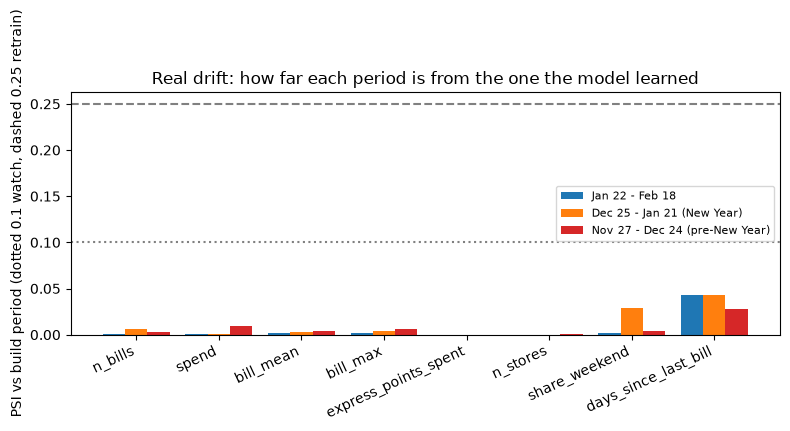

In [22]:
t0 = time.time()
PQ = (Path('..') / 'data_x5' / 'parquet' / 'purchases.parquet').as_posix()
SQL = f"""
WITH bills AS (
  SELECT client_id, transaction_id, MIN(transaction_datetime) dt, MAX(purchase_sum) bill_sum,
         MAX(ABS(express_points_spent)) exp_spent, ANY_VALUE(store_id) store_id,
         date_diff('day', CAST(MIN(transaction_datetime) AS DATE), DATE '2019-03-18') days_ago
  FROM '{PQ}' WHERE transaction_datetime < DATE '2019-03-19' GROUP BY 1, 2)
SELECT client_id, CAST(days_ago // 28 AS INT) w,
       COUNT(*) n_bills, SUM(bill_sum) spend, AVG(bill_sum) bill_mean, MAX(bill_sum) bill_max,
       SUM(exp_spent) express_points_spent, COUNT(DISTINCT store_id) n_stores,
       AVG(CASE WHEN dayofweek(dt) IN (0, 6) THEN 1 ELSE 0 END) share_weekend,
       MIN(days_ago) - 28 * CAST(days_ago // 28 AS INT) days_since_last_bill
FROM bills WHERE days_ago < 112 GROUP BY 1, 2"""
W = duckdb.sql(SQL).df()
LABEL = {0: 'Feb 19 - Mar 18 (model built)', 1: 'Jan 22 - Feb 18', 2: 'Dec 25 - Jan 21 (New Year)', 3: 'Nov 27 - Dec 24 (pre-New Year)'}
M = ['n_bills', 'spend', 'bill_mean', 'bill_max', 'express_points_spent', 'n_stores', 'share_weekend', 'days_since_last_bill']
ref = W[W.w == 0]
D1 = pd.DataFrame({LABEL[k]: {m: psi(ref[m], W.loc[W.w == k, m]) for m in M} for k in [1, 2, 3]}).round(3)
display(D1)
display(W.groupby('w')[['n_bills', 'spend', 'bill_mean']].mean().rename(index=LABEL).round(1))
worst = D1.max(); print(f'built in {time.time() - t0:.0f}s from {W.client_id.nunique():,} customers')
for k, v in worst.items(): print(f"  {k}: largest PSI {v:.3f} -> {'red: retrain' if v > 0.25 else 'amber: watch' if v > 0.1 else 'green: stable'}")
fig, ax = plt.subplots(figsize=(8, 3.8)); xs = np.arange(len(M))
for j, (k, col) in enumerate(zip(D1.columns, ['tab:blue', 'tab:orange', 'tab:red'])): ax.bar(xs + (j - 1) * 0.27, D1[k], 0.27, color=col, label=k)
ax.axhline(0.1, color='grey', ls=':'); ax.axhline(0.25, color='grey', ls='--')
ax.set_xticks(xs, M, rotation=25, ha='right'); ax.set_ylabel('PSI vs build period (dotted 0.1 watch, dashed 0.25 retrain)')
ax.set_title('Real drift: how far each period is from the one the model learned'); ax.legend(fontsize=8); plt.tight_layout(); plt.show()

**D2. Lift-ladder alarm.** Each campaign, check the real lift in the model's top, middle and bottom thirds (using the control group). A healthy model keeps the ladder in order: top > middle > bottom. Below is today's healthy ladder, the baseline for the alarm.

,real lift (pts)
third,
bottom third,0.95
middle third,2.88
top third,5.65


Alarm rule: top-third lift below 5.0 pts (1.5x the average) or ladder out of order -> investigate and retrain. Today: top third 5.7 pts.


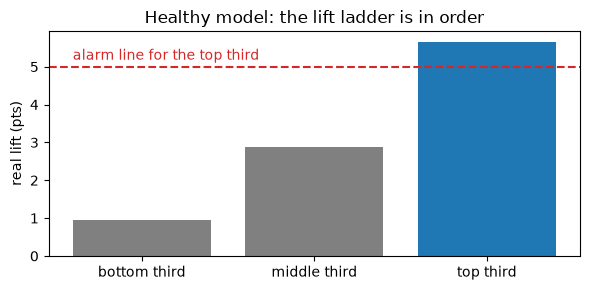

In [23]:
hold['third'] = pd.qcut(hold.champion.rank(method='first'), 3, labels=['bottom third', 'middle third', 'top third'])
lad = hold.groupby('third').apply(lambda d: 100 * (d[d.treatment_flg == 1].target.mean() - d[d.treatment_flg == 0].target.mean())).rename('real lift (pts)')
display(lad.round(2).to_frame())
print(f'Alarm rule: top-third lift below {1.5 * 100 * LIFT:.1f} pts (1.5x the average) or ladder out of order -> investigate and retrain. Today: top third {lad["top third"]:.1f} pts.')
fig, ax = plt.subplots(figsize=(6, 3)); ax.bar(lad.index.astype(str), lad.values, color=['grey', 'grey', 'tab:blue'])
ax.axhline(1.5 * 100 * LIFT, color='tab:red', ls='--'); ax.text(-0.4, 1.5 * 100 * LIFT + 0.2, 'alarm line for the top third', color='tab:red')
ax.set_ylabel('real lift (pts)'); ax.set_title('Healthy model: the lift ladder is in order'); plt.tight_layout(); plt.show()

## Part E · Best time to send: pilot design (X5 never varied send time, so this cannot be measured yet)
X5 sent every message at one moment, so send time was never tested. To measure it, randomise it:

| Group | Gets |
|---|---|
| Control | no message |
| Morning | message at 9 am |
| Evening | message at 7 pm |
| When due | message on the day the customer's usual gap runs out (overdue ratio reaches 1) |

Comparing two send times means comparing two messaged groups directly; differences between times are usually small, so the test must be big.

In [24]:
msg = BASE + LIFT
E = pd.DataFrame([{'difference between send times to detect (pts)': d * 100, 'customers per group': sample_size_per_group(msg, d),
                   'total customers (4 groups)': 4 * sample_size_per_group(msg, d)} for d in [0.01, 0.015, 0.02, 0.03]]).set_index('difference between send times to detect (pts)')
display(E)
print('Recommendation: test 1.5-2 pt differences (about 9,000-17,000 per group). A 1-pt difference needs ~37,000 per group, only worth it for very large bases.')

,customers per group,total customers (4 groups)
difference between send times to detect (pts),,
1.0,36097,144388
1.5,15992,63968
2.0,8965,35860
3.0,3957,15828


Recommendation: test 1.5-2 pt differences (about 9,000-17,000 per group). A 1-pt difference needs ~37,000 per group, only worth it for very large bases.


## Part F · The one-page playbook

In [25]:
PLAY = pd.DataFrame([
  ('Permanent control group', 'Hold back a random 10% (bases near 1 lakh) or 2% (near 10 lakh) every campaign', 'Proves the profit; catches a halving of lift'),
  ('Explore and record', 'Targeting keeps ~20% randomness and records each customer chance (or a random slice of ~30,000+)', 'Clean data to retrain; targeted-only data makes the model worse than random'),
  ('Report', 'Always contacted vs control: extra buyers, extra profit, 95% range', 'Naive reports overstate ~9x and can make a losing campaign look profitable'),
  ('Drift alarm', 'Monthly PSI on every customer measure vs the build period', 'Amber 0.1-0.25 watch; red over 0.25 retrain; festive months shift behaviour'),
  ('Lift-ladder alarm', 'Each campaign: real lift in top / middle / bottom thirds', 'Top third under 1.5x average or out of order: retrain'),
  ('Retrain', 'Quarterly on exploration data (weighted by recorded chance), or at once on a red alarm', 'Re-run the Step 4 model check before switching'),
  ('Send-time test', 'Once: control / morning / evening / when due, ~10-17k per group', 'Adds the best time to send'),
], columns=['what', 'how', 'why']).set_index('what'); display(PLAY)

,how,why
what,,
Permanent control group,Hold back a random 10% (bases near 1 lakh) or 2% (near 10 lakh) every campaign,Proves the profit; catches a halving of lift
Explore and record,Targeting keeps ~20% randomness and records each customer chance (or a random slice of...,Clean data to retrain; targeted-only data makes the model worse than random
Report,"Always contacted vs control: extra buyers, extra profit, 95% range",Naive reports overstate ~9x and can make a losing campaign look profitable
Drift alarm,Monthly PSI on every customer measure vs the build period,Amber 0.1-0.25 watch; red over 0.25 retrain; festive months shift behaviour
Lift-ladder alarm,Each campaign: real lift in top / middle / bottom thirds,Top third under 1.5x average or out of order: retrain
Retrain,"Quarterly on exploration data (weighted by recorded chance), or at once on a red alarm",Re-run the Step 4 model check before switching
Send-time test,"Once: control / morning / evening / when due, ~10-17k per group",Adds the best time to send


## K8 verdict

In [26]:
for k_, v in CHECKS.items(): print(f'{"PASS" if v else "FAIL"}  {k_}')
print('\nK8 VERDICT:', 'PASS' if all(CHECKS.values()) else 'REVIEW')

PASS  Naive report overstates the true effect (at least 3x)
PASS  Decision flip: naive shows big profit, fair shows break-even or loss (bottom half, AI calls)
PASS  Sample-size formula matches simulation (power 77-83%)
PASS  Targeted-only retraining fails (under half the clean Qini)
PASS  Enough random exploration recovers most quality (60%+ of clean Qini)
PASS  Using the recorded chance beats ignoring it
PASS  Drift alarm quiet when nothing changed (all PSI under 0.1)
PASS  Drift alarm fires on a deliberate shift (a PSI over 0.25)

K8 VERDICT: PASS


## Your notes
- Why does the naive report overstate so much?
- Why can't a model be retrained on data from a targeted campaign?
- What size of control group would you propose for BASIC's lead base?